# Function 2: local GP around the incumbent

Fit an RBF Gaussian process using observations through Week 5 that are closest to the best observed input. This is a read-only diagnostic: it does not select or export a submission.

In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_bbo import CONFIG
from bayesian_bbo.data import Observations, load_observations
from bayesian_bbo.kernels import make_comparison_kernels
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig
from bayesian_bbo.visualisation import plot_gp_2d

FUNCTION_ID = 2
CURRENT_WEEK = 5
NEAREST_COUNT = 9
ALPHA = 0.1

data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_2').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
observations = load_observations(matches[0], FUNCTION_ID, up_to_week=CURRENT_WEEK)

## Choose the neighborhood

The incumbent is the input with the highest measured output through Week 5. Rank all observations by Euclidean distance to it in the normalized input space, including the incumbent itself. Ties retain their original observation order.

Nine points are an exploratory choice: in the current data the ninth and tenth distances are approximately 0.427 and 0.683, leaving a noticeable gap. This does not establish a true basin or an optimal neighborhood size. Change `NEAREST_COUNT` to explore sensitivity; a time-ordered backtest would be needed to assess predictive performance without using future observations.

In [2]:
if not 1 <= NEAREST_COUNT <= len(observations.inputs):
    raise ValueError('NEAREST_COUNT must be between 1 and the number of observations.')

incumbent = observations.best_input
distances = np.linalg.norm(observations.inputs - incumbent, axis=1)
order = np.argsort(distances, kind='stable')
selected = order[:NEAREST_COUNT]
if observations.best_index not in selected:
    raise ValueError('The selected neighborhood must contain the incumbent.')

local_observations = Observations(
    inputs=observations.inputs[selected],
    outputs=observations.outputs[selected],
    dimension=observations.dimension,
    expected_outputs=observations.expected_outputs[selected],
    stds=observations.stds[selected],
    weeks=observations.weeks[selected],
)
ranked = pd.DataFrame({
    'observation_index': order,
    'week': observations.weeks[order],
    'x1': observations.inputs[order, 0],
    'x2': observations.inputs[order, 1],
    'output': observations.outputs[order],
    'distance_to_incumbent': distances[order],
    'included': np.arange(len(order)) < NEAREST_COUNT,
})
print(f'Incumbent: {incumbent}; observed output: {observations.best_output:.6f}')
print(f'Using {len(selected)} of {len(order)} observations through Week {CURRENT_WEEK}.')
display(ranked)

Incumbent: [0.70263656 0.9265642 ]; observed output: 0.611205
Using 9 of 15 observations through Week 5.


,observation_index,week,x1,x2,output,distance_to_incumbent,included
0,9,0,0.702637,0.926564,0.611205,0.000000,True
1,14,5,0.692637,0.926564,0.610531,0.010000,True
2,10,1,0.802058,0.932779,0.126341,0.099615,True
3,5,0,0.577713,0.771973,0.023106,0.198757,True
4,13,4,0.500000,0.926564,0.233409,0.202637,True
5,1,0,0.877791,0.778628,0.420586,0.229269,True
6,3,0,0.845275,0.711120,0.293993,0.258383,True
7,6,0,0.438166,0.685018,0.244619,0.358175,True
8,12,3,0.702637,0.500000,0.594386,0.426564,True
9,4,0,0.454647,0.290455,0.214965,0.682740,False


## Fit and plot

Use the same RBF kernel, length cap, and Week 6 proposal setting `xi = 0.1 * std(all outputs)` as the global model. The plot spans the full unit square, but predictions far from the selected points are extrapolations from this local fit. The EI marker is the maximum on the plotting grid, not a submitted candidate or a guaranteed global optimum.

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


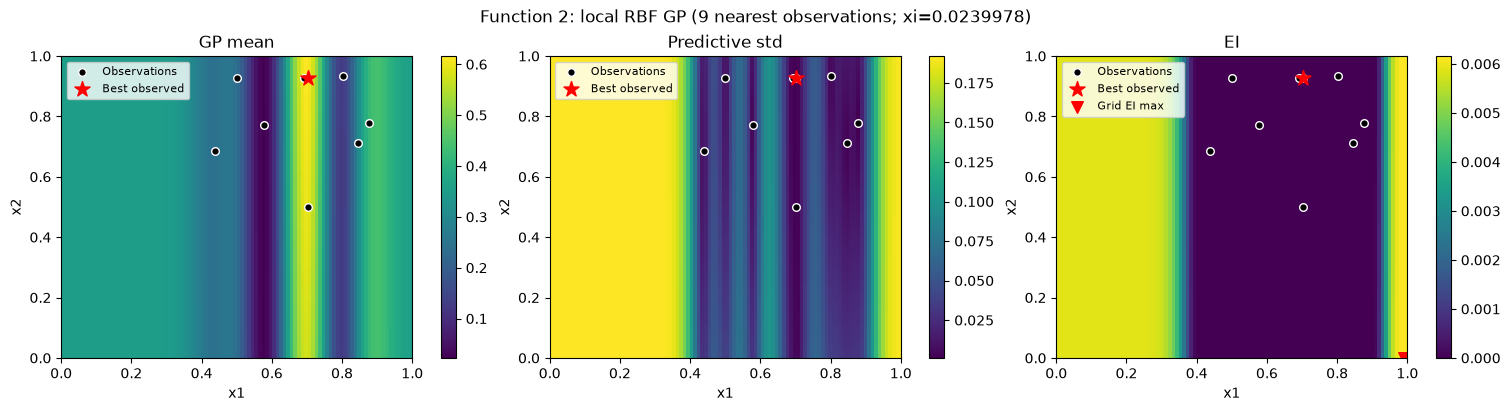

In [3]:
kernel = make_comparison_kernels(
    observations.dimension, CONFIG['length_caps'][FUNCTION_ID],
)['RBF']
xi = ALPHA * np.std(observations.outputs)
optimizer = BayesianOptimizer(
    local_observations, OptimisationConfig(budget=1, kernel=kernel, xi=xi),
)
figure, axes = plot_gp_2d(optimizer, n=100)
figure.suptitle(f'Function 2: local RBF GP ({NEAREST_COUNT} nearest observations; xi={xi:.6g})')
display(figure)
plt.close(figure)